# The Evolution of Tech Skills
CS 418 Fall 2026

**Data:** Hacker News monthly “Who is Hiring” threads. **Question:** How have requested tech skills changed, and what can job postings tell us about AI and entry-level roles?

**Limitations:** These posts are not a representative sample of the entire labor market; skill keyword mentions do not prove a skill is required.


In [1]:
from pathlib import Path
import pandas as pd
DATA_DIR = Path("../data/processed")
if not DATA_DIR.exists():
    DATA_DIR = Path("data/processed")
cleaned_df = pd.read_csv(DATA_DIR / "jobs_cleaned.csv")
analysis_df = pd.read_csv(DATA_DIR / "jobs_analysis.csv")
print("Cleaned posts:", len(cleaned_df))
print("Skill-analysis posts:", len(analysis_df))
display(cleaned_df.head())

Cleaned posts: 15197
Skill-analysis posts: 9124


,id,thread_id,date,year,month,company,role,location,remote,work_mode,salary,skills,skill_count,is_likely_job,text
0,34219342,34219335,2023-01-02 16:01:37+00:00,2023,1,Aha!,Rails / React / Devops,REMOTE,True,remote,NaN,"react, ruby, rails",3,True,Aha! ( https://www.aha.io ) | Rails / React / ...
1,34219356,34219335,2023-01-02 16:02:09+00:00,2023,1,Twaice,NaN,"Engineering, UX",True,remote,NaN,NaN,0,True,"Twaice | Engineering, UX | Munich, Germany or ..."
2,34219392,34219335,2023-01-02 16:04:17+00:00,2023,1,Symmetry Investments,Many Varied Roles,"REMOTE GLOBALLY or VISA (London, Hong Kong, Si...",True,remote,NaN,"python, typescript, rust, c++, git, linux",6,True,Symmetry Investments | Many Varied Roles | REM...
3,34219414,34219335,2023-01-02 16:05:35+00:00,2023,1,Source,NaN,San Francisco / Bay Area: Remote,True,remote,NaN,go,1,True,Source | San Francisco / Bay Area: Remote | Fu...
4,34219470,34219335,2023-01-02 16:08:43+00:00,2023,1,"Apple, Inc.",NaN,New York,False,unknown,NaN,NaN,0,True,"Apple, Inc. | New York | Cheltenham | Cupertin..."


In [2]:
print("Duplicate IDs:", cleaned_df["id"].duplicated().sum())
print("Years:", sorted(cleaned_df["year"].dropna().unique()))
display(cleaned_df.isna().sum().rename("Missing values"))

Duplicate IDs: 0
Years: [np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


id                   0
thread_id            0
date                 0
year                 0
month                0
company           1229
role              5704
location          1649
remote               0
work_mode            0
salary           15197
skills            5603
skill_count          0
is_likely_job        0
text                 0
Name: Missing values, dtype: int64

## Changes since proposal

Our proposal considered hiring posts from 2011 onward. Our current dataset instead covers January 2023 through November 2026 (47 monthly threads), focusing on recent skill trends. The 2026 data is incomplete.

**Team to confirm:** Any other scope or modeling changes.

## Data preparation

We collected **15,252 raw Hacker News comments**, producing **15,197 unique cleaned records**. Our Python pipeline removed HTML formatting, extracted company, role, and location when possible, assigned heuristic work-mode labels, and detected mentions of **26 tracked technical skills**. A heuristic also flags likely hiring posts.

For skill analysis, we selected likely hiring posts mentioning at least one tracked skill: **9,124 posts**. We retain the full cleaned dataset for analyses requiring a different denominator.

**Limitations:** Hiring-post detection and extracted roles, companies, locations, and work modes are not fully validated. Salary was not extracted. Keyword mentions do not establish required skills. Our vocabulary misses other technologies, and this Hacker News sample does not represent the whole labor market.

## Exploratory data analysis

Among the 9,124 selected posts, the most frequently mentioned skills were **React (3,356)**, **Python (3,345)**, **TypeScript (3,000)**, **AWS (2,096)**, and **Go (1,524)**. Posts mention an average of **2.73** tracked skills. The following chart shows the top ten skills.

**Team to add:** Five hypothesis-driven charts with hypotheses, results, interpretations, and contributors. This descriptive chart is separate from those required analyses.

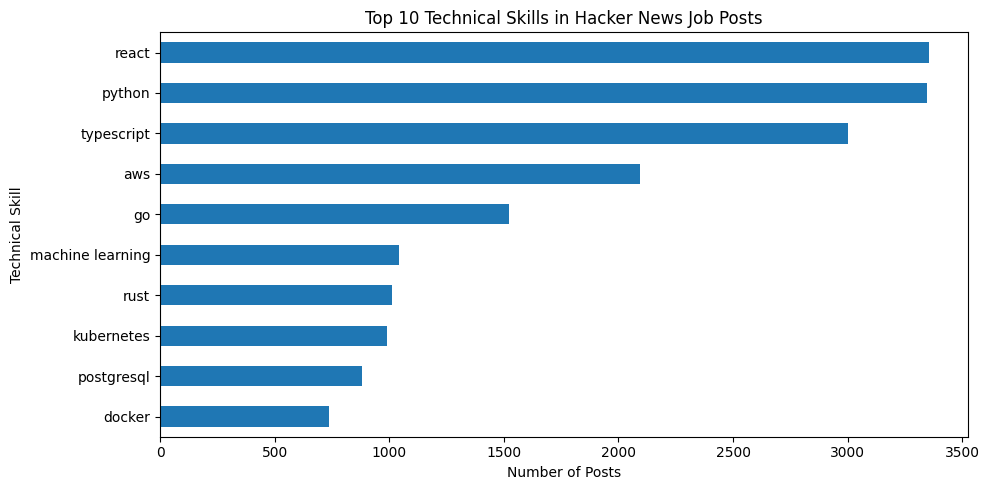

In [3]:
import matplotlib.pyplot as plt
from collections import Counter
counts = Counter()
for value in analysis_df["skills"].dropna():
    counts.update(skill.strip() for skill in value.split(",") if skill.strip())
top = pd.Series(dict(counts.most_common(10))).sort_values()
ax = top.plot(kind="barh", figsize=(10, 5))
ax.set_title("Top 10 Technical Skills in Hacker News Job Posts")
ax.set_xlabel("Number of Posts")
ax.set_ylabel("Technical Skill")
plt.tight_layout()
plt.show()

## Machine learning and baselines

**Team to add:** Two different models with clearly defined targets, features, train/test splits, baseline comparisons, metrics, and interpretations. Validate seniority labels before relying on them for classification.

## Reflection

Inconsistent job-post formatting and heuristic extraction are key risks. Filtering for posts with recognized skills also changes the analysis population. The dataset is still useful for exploring trends within the Hacker News hiring community if we communicate these limits and validate important fields.

**Team to add:** Actual findings and challenges from teammates' visualizations and models, and whether the project remains on track.

## Next steps

Before the November 13 progress report, merge team analyses, rerun the notebook, and export the required PDF. For the final project, validate extracted labels, improve parsing as needed, and interpret trends with consistent denominators.

**Team to confirm:** Owners and dates for remaining work.